# Bài 3 v4 · Đánh giá phân loại
PGS.TS. Nguyễn Văn Hậu

Mở notebook trong thư mục Bai03_v4. Cài requirements.txt nếu môi trường chưa có. Dữ liệu đã có sẵn nên thực hành không cần mạng. Đây là tái lập case lịch sử đã công bố; không lựa chọn lại bằng test.


In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'source/metrics_lab.py').exists():
    raise RuntimeError('Mở notebook trong thư mục Bai03_v4 chứa source/ và data/.')
sys.path.insert(0,str(ROOT/'source'))
from metrics_lab import (run,measure,toy_data,predict_votes,select_policy,
    np,pd,confusion_matrix,roc_auc_score,average_precision_score)
report=run()
print('Kiểm khoa học:',report['status'],report['checks_count'])
print('Kết quả test lịch sử:',report['base'])


Kiểm khoa học: pass 62
Kết quả test lịch sử: {'tn': 892, 'fp': 12, 'fn': 17, 'tp': 111, 'n': 1032, 'alerts': 123, 'accuracy': 0.9718992248062015, 'precision': 0.9024390243902439, 'recall': 0.8671875, 'f1': 0.8844621513944223, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 77, 'cost_fp_5fn': 97}


## 1. Một hàng thật trước khi đọc chỉ số
Nhãn y là đáp án nguồn; score là tỷ lệ phiếu, prediction là quyết định ở m6.


In [2]:
test=pd.read_csv(ROOT/'data/test_predictions.csv')
validation=pd.read_csv(ROOT/'data/validation_predictions.csv')
print('Test:',test.y.value_counts().to_dict())
print('Validation:',validation.y.value_counts().to_dict())
for record in [1056,1501]:
    row=test.loc[test.source_record==record].iloc[0]
    print(record,repr(row.text))
    print('y / votes / score / prediction:',row.y,row.votes,row.score,row.prediction)


Test: {0: 904, 1: 128}
Validation: {0: 903, 1: 129}
1056 'HIYA COMIN 2 BRISTOL 1 ST WEEK IN APRIL. LES GOT OFF + RUDI ON NEW YRS EVE BUT I WAS SNORING.THEY WERE DRUNK! U BAK AT COLLEGE YET? MY WORK SENDS INK 2 BATH.'
y / votes / score / prediction: 0 6 0.5454545454545454 1
1501 'SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO'
y / votes / score / prediction: 1 4 0.3636363636363636 0


## 2. Tự đếm và dùng đúng nhóm mẫu số
Hàng thật, cột dự đoán; spam là lớp dương. Tính tay trước khi đối chiếu.


In [3]:
toy=toy_data()
for tau in [.5,.8]:
    pred=(toy.score>=tau).astype(int)
    groups={name:toy.loc[(toy.y==y)&(pred==p),'id'].tolist()
        for name,y,p in [('TN',0,0),('FP',0,1),('FN',1,0),('TP',1,1)]}
    print('tau=',tau,'IDs=',groups)
    print(measure(toy.y,pred))
assert measure(toy.y,toy.score>=.5)['f1']==.8


tau= 0.5 IDs= {'TN': ['G', 'H', 'I', 'J'], 'FP': ['B', 'E'], 'FN': [], 'TP': ['A', 'C', 'D', 'F']}
{'tn': 4, 'fp': 2, 'fn': 0, 'tp': 4, 'n': 10, 'alerts': 6, 'accuracy': 0.8, 'precision': 0.6666666666666666, 'recall': 1.0, 'f1': 0.8, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 10, 'cost_fp_5fn': 2}
tau= 0.8 IDs= {'TN': ['E', 'G', 'H', 'I', 'J'], 'FP': ['B'], 'FN': ['D', 'F'], 'TP': ['A', 'C']}
{'tn': 5, 'fp': 1, 'fn': 2, 'tp': 2, 'n': 10, 'alerts': 3, 'accuracy': 0.7, 'precision': 0.6666666666666666, 'recall': 0.5, 'f1': 0.5714285714285714, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 7, 'cost_fp_5fn': 11}


## 3. Precision không có bảo đảm đơn điệu
Bỏ một TP khỏi nhóm cảnh báo có thể làm precision giảm.


In [4]:
for tau in [.85,.9]:
    pred=toy.score>=tau
    print(tau,toy.loc[pred,'id'].tolist(),'P=',measure(toy.y,pred)['precision'])
assert measure(toy.y,toy.score>=.85)['precision']>measure(toy.y,toy.score>=.9)['precision']
edge=measure([0,0],[0,0])
print('Chỉ có TN; giá trị báo cáo và cờ definedness:',edge)


0.85 ['A', 'B', 'C'] P= 0.6666666666666666
0.9 ['A', 'B'] P= 0.5
Chỉ có TN; giá trị báo cáo và cờ definedness: {'tn': 2, 'fp': 0, 'fn': 0, 'tp': 0, 'n': 2, 'alerts': 0, 'accuracy': 1.0, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'precision_defined': False, 'recall_defined': False, 'f1_count_defined': False, 'zero_division': 0, 'cost_5fp_fn': 0, 'cost_fp_5fn': 0}


## 4. Chọn trên validation, khóa chính sách
Hai chi phí là giả định; tập ứng viên gồm cả m0 và m12.


In [5]:
scan=[dict(min_votes=m,**measure(validation.y,predict_votes(validation.votes,m))) for m in range(13)]
chosen={key:select_policy(scan,key) for key in ['cost_5fp_fn','cost_fp_5fn']}
for key,best in chosen.items():
    print(key,'chon m=',best['min_votes'],'chi phi validation=',best[key])
    print('Test lich su:',measure(test.y,predict_votes(test.votes,best['min_votes'])))
assert chosen['cost_5fp_fn']['min_votes']==8
assert chosen['cost_fp_5fn']['min_votes']==4


cost_5fp_fn

 chon m= 8 chi phi validation= 39
Test lich su: {'tn': 897, 'fp': 7, 'fn': 21, 'tp': 107, 'n': 1032, 'alerts': 114, 'accuracy': 0.9728682170542635, 'precision': 0.9385964912280702, 'recall': 0.8359375, 'f1': 0.8842975206611571, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 56, 'cost_fp_5fn': 112}
cost_fp_5fn chon m= 4 chi phi validation= 77
Test lich su: {'tn': 881, 'fp': 23, 'fn': 14, 'tp': 114, 'n': 1032, 'alerts': 137, 'accuracy': 0.9641472868217055, 'precision': 0.8321167883211679, 'recall': 0.890625, 'f1': 0.8603773584905661, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 129, 'cost_fp_5fn': 93}


## 5. Theo dõi hai ID qua ba chính sách
Không đổi y,score hoặc mô hình trong phép so.


In [6]:
for record in [1056,1501]:
    row=test.loc[test.source_record==record].iloc[0]
    for m in [4,6,8]:
        pred=int(row.votes>=m)
        outcome=['TN','FP','FN','TP'][2*int(row.y)+pred]
        print(record,'m',m,'y',row.y,'prediction',pred,outcome)


1056 m 4 y 0 prediction 1 FP
1056 m 6 y 0 prediction 1 FP
1056 m 8 y 0 prediction 0 TN
1501 m 4 y 1 prediction 1 TP
1501 m 6 y 1 prediction 0 FN
1501 m 8 y 1 prediction 0 FN


## 6. Score cho xếp hạng; nhãn quyết định cho bốn ô
AUC/AP từ cùng score giữ nguyên khi chỉ đổi ngưỡng.


ROC-AUC(score): 0.9690611172566371


AP(score): 0.9267043811583162
m 4 {'tn': 881, 'fp': 23, 'fn': 14, 'tp': 114, 'n': 1032, 'alerts': 137, 'accuracy': 0.9641472868217055, 'precision': 0.8321167883211679, 'recall': 0.890625, 'f1': 0.8603773584905661, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 129, 'cost_fp_5fn': 93}
m 6 {'tn': 892, 'fp': 12, 'fn': 17, 'tp': 111, 'n': 1032, 'alerts': 123, 'accuracy': 0.9718992248062015, 'precision': 0.9024390243902439, 'recall': 0.8671875, 'f1': 0.8844621513944223, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 77, 'cost_fp_5fn': 97}
m 8 {'tn': 897, 'fp': 7, 'fn': 21, 'tp': 107, 'n': 1032, 'alerts': 114, 'accuracy': 0.9728682170542635, 'precision': 0.9385964912280702, 'recall': 0.8359375, 'f1': 0.8842975206611571, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 56, 'cost_fp_5fn': 112}


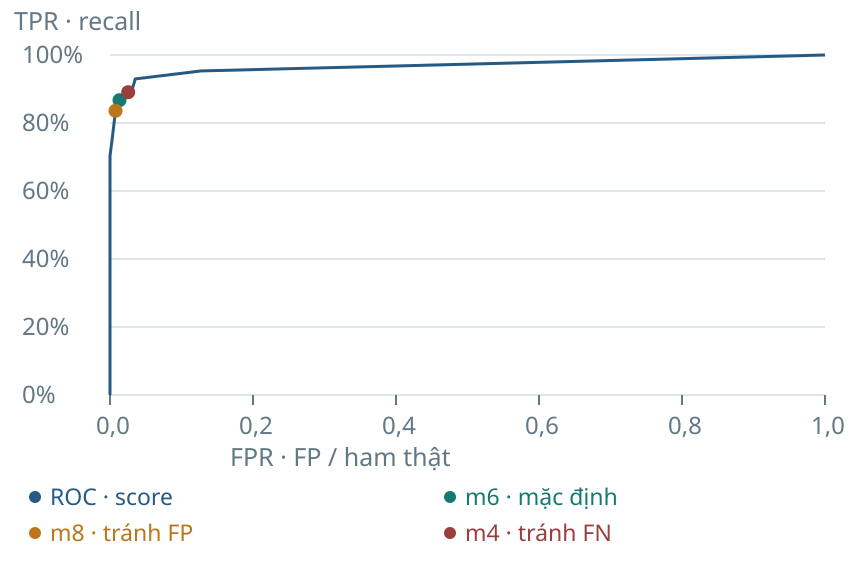

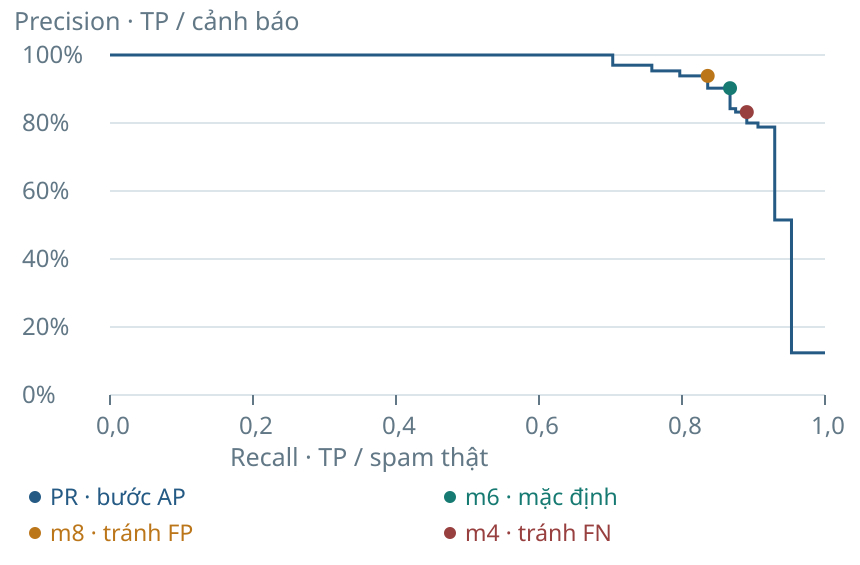

In [7]:
print('ROC-AUC(score):',roc_auc_score(test.y,test.score))
print('AP(score):',average_precision_score(test.y,test.score))
for m in [4,6,8]:
    print('m',m,measure(test.y,predict_votes(test.votes,m)))
try:
    from IPython.display import SVG,display
except ImportError:
    print('Trong Jupyter có thể xem SVG; mở source/science/roc.svg và pr.svg để xem ngoài notebook.')
else:
    display(SVG(filename=str(ROOT/'source/science/roc.svg')))
    display(SVG(filename=str(ROOT/'source/science/pr.svg')))


## 7. Phiếu cuối buổi
Tự tính trước: TP3,FP2,FN2,TN13. Giải thích vì sao hai mẫu số cùng 5 chưa có nghĩa cùng nhóm.


In [8]:
exit_result=measure([1]*5+[0]*15,[1]*3+[0]*2+[1]*2+[0]*13)
print(exit_result)
assert exit_result['precision']==exit_result['recall']==exit_result['f1']==.6
print('Kết luận cần có mục tiêu, dữ liệu lựa chọn, lịch sử test và một giới hạn cụ thể.')


{'tn': 13, 'fp': 2, 'fn': 2, 'tp': 3, 'n': 20, 'alerts': 5, 'accuracy': 0.8, 'precision': 0.6, 'recall': 0.6, 'f1': 0.6, 'precision_defined': True, 'recall_defined': True, 'f1_count_defined': True, 'zero_division': 0, 'cost_5fp_fn': 12, 'cost_fp_5fn': 12}
Kết luận cần có mục tiêu, dữ liệu lựa chọn, lịch sử test và một giới hạn cụ thể.
